# HIVE — Fluorescence Image Analysis Walkthrough

**High-Processing Imaging Visualization Engine**

This notebook is a self-contained tour of the HIVE pipeline. It generates its own
synthetic phantoms with **known ground truth**, so every measurement below can be checked
against the right answer — you can run it end-to-end with no data of your own.

It covers:

1. The two-image contract — the single most important design rule in HIVE
2. Background subtraction (percentile / Gaussian / top-hat)
3. Otsu thresholding, with an interactive threshold explorer
4. Segmentation cleanup (debris, edges, holes)
5. Intensity quantification that is actually comparable between images
6. Arborization: skeletonization, branch topology, and Sholl analysis
7. 3D reconstruction and the rotating-projection GIF

---

## Why this notebook opens with a warning

The predecessor to this pipeline measured intensity on a **contrast-enhanced,
per-image min-max normalized** image. That single choice made every intensity number
it exported scientifically invalid. Measured on synthetic data with known answers:

| Scenario | True | Legacy reported |
|---|---|---|
| Two samples with a 3× brightness difference | 3.00× | **1.00×** |
| Z-stack with a 33% axial intensity gradient | 1.333× | **1.000×** |

A real biological difference reported as *no difference at all*. Section 1 reproduces
this from first principles, because understanding it is the point of the redesign.

---
## 0. Setup — install dependencies

Run this section once, before anything else.

HIVE's dependencies are listed in `requirements.txt`. The cell below installs only what's
actually **missing**, so re-running the notebook is fast rather than re-resolving the whole
stack every time.

Two things worth knowing:

- **It installs into *this kernel*, not your shell.** The cell uses
  `sys.executable -m pip`, not `!pip install`. `!pip` runs whichever pip happens to be first
  on the shell `PATH`, which is very often a *different* interpreter than the one running
  this notebook — the classic "I definitely installed it, so why is it still
  `ModuleNotFoundError`?" trap.
- **HIVE itself isn't installed** — it's imported from this folder. So the notebook must be
  run from the project root (the directory containing `hive/`). The cell checks this and
  says so plainly instead of letting you discover it eight cells later.

Cellpose, PyTorch and PyImageJ are **not** installed here. They're large, slow, and nothing
in this notebook needs them.

> **Reproducibility.** `requirements.txt` sets lower bounds. For an environment pinned to the
> exact versions HIVE was verified against — which is what you want when re-running an
> analysis for a paper revision — use `pip install -r requirements-lock.txt` instead.


In [1]:
# Install HIVE's dependencies into THIS kernel, skipping anything already present.
import importlib
import importlib.util
import subprocess
import sys
from pathlib import Path

# import name -> pip requirement (import name != pip name for several of these)
REQUIRED = {
    'numpy':      'numpy>=1.24',
    'scipy':      'scipy>=1.10',
    'skimage':    'scikit-image>=0.19',   # >=0.19 for the `intensity_mean` regionprops name
    'pandas':     'pandas>=2.0',
    'tifffile':   'tifffile>=2023.1.1',
    'matplotlib': 'matplotlib>=3.7',      # colormaps for 3D rendering
    'PIL':        'pillow>=9.5',          # GIF encoding
    'plotly':     'plotly>=5.14',         # interactive threshold explorer
    'openpyxl':   'openpyxl>=3.1',        # Excel reports
}

missing = [req for mod, req in REQUIRED.items() if importlib.util.find_spec(mod) is None]

if missing:
    print(f'installing {len(missing)} missing package(s): {", ".join(missing)}\n')
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
        importlib.invalidate_caches()   # let this session see what we just installed
        print('\ninstall complete. If an import below still fails, restart the kernel.')
    except subprocess.CalledProcessError:
        raise SystemExit(
            'pip install failed (offline, or no permission to write to this environment).\n'
            'Install manually, then re-run this cell:\n'
            '    pip install -r requirements.txt'
        )
else:
    print('all dependencies already present\n')

# Report what we actually got — a version mismatch is easier to spot here than in a traceback.
for mod, req in REQUIRED.items():
    version = getattr(importlib.import_module(mod), '__version__', 'unknown')
    print(f'  {req.split(">=")[0]:<14} {version}')

# HIVE is imported from this folder rather than installed, so the working directory matters.
if not (Path.cwd() / 'hive').is_dir():
    raise RuntimeError(
        f"No 'hive' package found in {Path.cwd()}.\n"
        "Run this notebook from the HIVE_Final project root — the folder that contains "
        "hive/, app.py and requirements.txt."
    )
print(f'\nhive package found in {Path.cwd()}')


all dependencies already present

  numpy          2.4.6
  scipy          1.18.0
  scikit-image   0.26.0
  pandas         3.0.3
  tifffile       2026.6.1
  matplotlib     3.11.0
  pillow         12.3.0
  plotly         6.7.0
  openpyxl       3.1.5

hive package found in /home/rush/Downloads/HIVE-main


In [2]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
sys.path.insert(0, str(Path.cwd()))

# Explicit seed: every stochastic step in this notebook is reproducible.
RNG = np.random.default_rng(0)

plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'magma',
                     'axes.spines.top': False, 'axes.spines.right': False})
print('HIVE notebook ready')

HIVE notebook ready


---
## 1. The two-image contract

Fluorescence analysis asks two different questions of the same data, and they want
**opposite** things:

| Question | Wants | Operations |
|---|---|---|
| *Where are the objects?* | Maximum contrast — distort freely | blur, CLAHE, normalize |
| *How bright are they?* | Zero distortion — preserve the physical scale | background subtraction only |

CLAHE and min-max scaling are **great** for the first and **fatal** for the second.
HIVE therefore builds two images and never confuses them:

```
raw → select_channel → baseline subtract ──→ MEASUREMENT image  (quantitative)
                                │
                                └→ blur → CLAHE → normalize ──→ SEGMENTATION image  (detection only)
```

Let's prove why this matters.

In [3]:
# Two images of the SAME structure. The only difference is real biology:
# the second is genuinely 4x brighter above background.
def make_blob(level, background=100, size=80):
    img = np.full((size, size), background, dtype=np.float32)
    img[30:50, 30:50] = level
    return img

dim    = make_blob(300)   # 200 above background
bright = make_blob(900)   # 800 above background  -> a true 4x difference

true_ratio = (900 - 100) / (300 - 100)
print(f'TRUE background-corrected ratio: {true_ratio:.2f}x')

TRUE background-corrected ratio: 4.00x


In [4]:
# THE LEGACY APPROACH: normalize each image to its own min/max, then measure it.
def legacy_preprocess(img):
    img = (img - img.min()) / (img.max() - img.min())   # <-- the fatal line
    return img

legacy_dim, legacy_bright = legacy_preprocess(dim), legacy_preprocess(bright)
l_d = legacy_dim[30:50, 30:50].mean()
l_b = legacy_bright[30:50, 30:50].mean()

print(f'legacy dim    blob mean = {l_d:.3f}')
print(f'legacy bright blob mean = {l_b:.3f}')
print(f'legacy REPORTED ratio   = {l_b / l_d:.2f}x   <-- the 4x biology has vanished')
print()
print('Each image was divided by its OWN maximum, so each blob became 1.0.')
print('The measurement now describes the normalization, not the sample.')

legacy dim    blob mean = 1.000
legacy bright blob mean = 1.000
legacy REPORTED ratio   = 1.00x   <-- the 4x biology has vanished

Each image was divided by its OWN maximum, so each blob became 1.0.
The measurement now describes the normalization, not the sample.


In [5]:
# THE HIVE APPROACH: measure on the background-corrected image, original scale.
from hive.preprocessing import prepare_image
from hive.config import PreprocessConfig

pre = PreprocessConfig(baseline_method='percentile', baseline_percentile=25,
                       gaussian_sigma=0, use_clahe=True)

p_dim    = prepare_image(dim,    pre, channel='gray')
p_bright = prepare_image(bright, pre, channel='gray')

h_d = p_dim.measurement[30:50, 30:50].mean()
h_b = p_bright.measurement[30:50, 30:50].mean()

print(f'HIVE dim    blob mean = {h_d:.1f}')
print(f'HIVE bright blob mean = {h_b:.1f}')
print(f'HIVE REPORTED ratio   = {h_b / h_d:.2f}x   <-- matches the true {true_ratio:.2f}x')
print()
print('Note CLAHE was ENABLED above — it just never touched the measurement image.')

HIVE dim    blob mean = 200.0
HIVE bright blob mean = 800.0
HIVE REPORTED ratio   = 4.00x   <-- matches the true 4.00x

Note CLAHE was ENABLED above — it just never touched the measurement image.


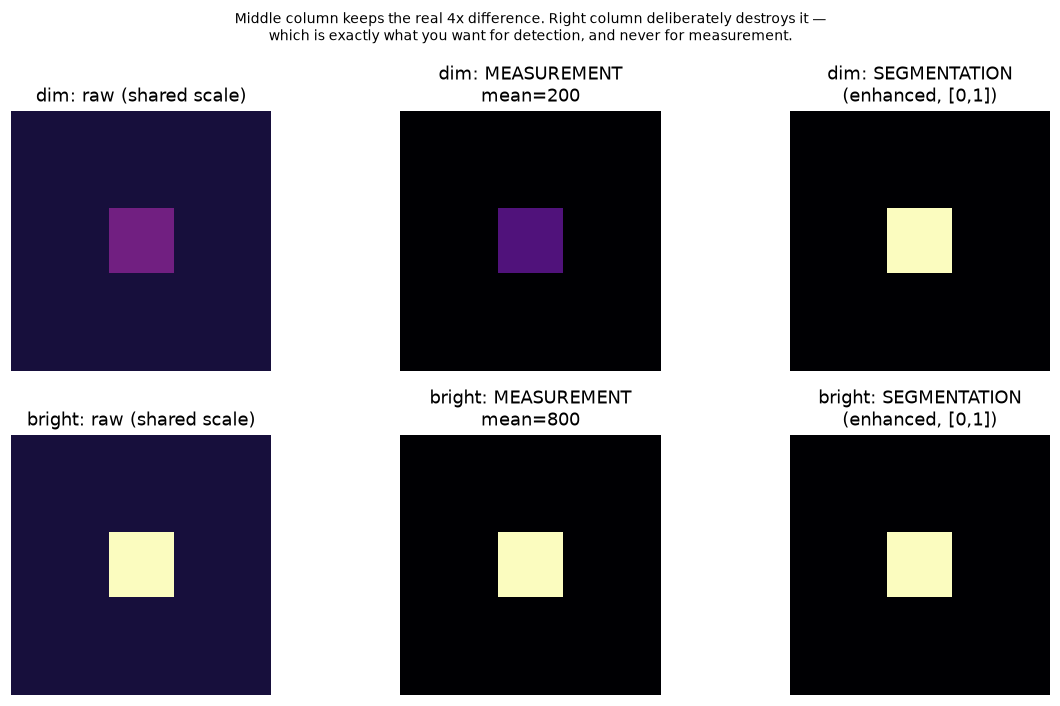

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for row, (name, prepared, raw) in enumerate([('dim', p_dim, dim), ('bright', p_bright, bright)]):
    axes[row, 0].imshow(raw, vmin=0, vmax=900)
    axes[row, 0].set_title(f'{name}: raw (shared scale)')
    axes[row, 1].imshow(prepared.measurement, vmin=0, vmax=800)
    axes[row, 1].set_title(f'{name}: MEASUREMENT\nmean={prepared.measurement[30:50,30:50].mean():.0f}')
    axes[row, 2].imshow(prepared.segmentation, vmin=0, vmax=1)
    axes[row, 2].set_title(f'{name}: SEGMENTATION\n(enhanced, [0,1])')
for ax in axes.ravel(): ax.axis('off')
fig.suptitle('Middle column keeps the real 4x difference. Right column deliberately destroys it —\n'
             'which is exactly what you want for detection, and never for measurement.', fontsize=9)
plt.tight_layout(); plt.show()

---
## 2. Background subtraction

Fluorescence images carry a background from autofluorescence, scattered light and camera
offset. Subtracting it is what makes *integrated* intensity meaningful.

Three estimators, with real trade-offs:

- **`percentile`** — subtracts one global scalar (a low intensity percentile).
  Cheap and robust, but blind to illumination gradients. Assumes background occupies
  at least *p*% of the frame; fails on densely labelled samples.
- **`smooth`** — subtracts a Gaussian-blurred estimate. Handles gradients, but a Gaussian
  is a *symmetric* filter, not a lower envelope, so it overestimates background near bright
  objects and leaves a **dark halo** after subtraction.
- **`tophat`** — morphological white top-hat (grey opening). Same family as ImageJ's
  rolling-ball. Estimates a true lower envelope, so no halo. **Default.**

The top-hat radius must **exceed your largest real feature** — too small and it eats your signal.

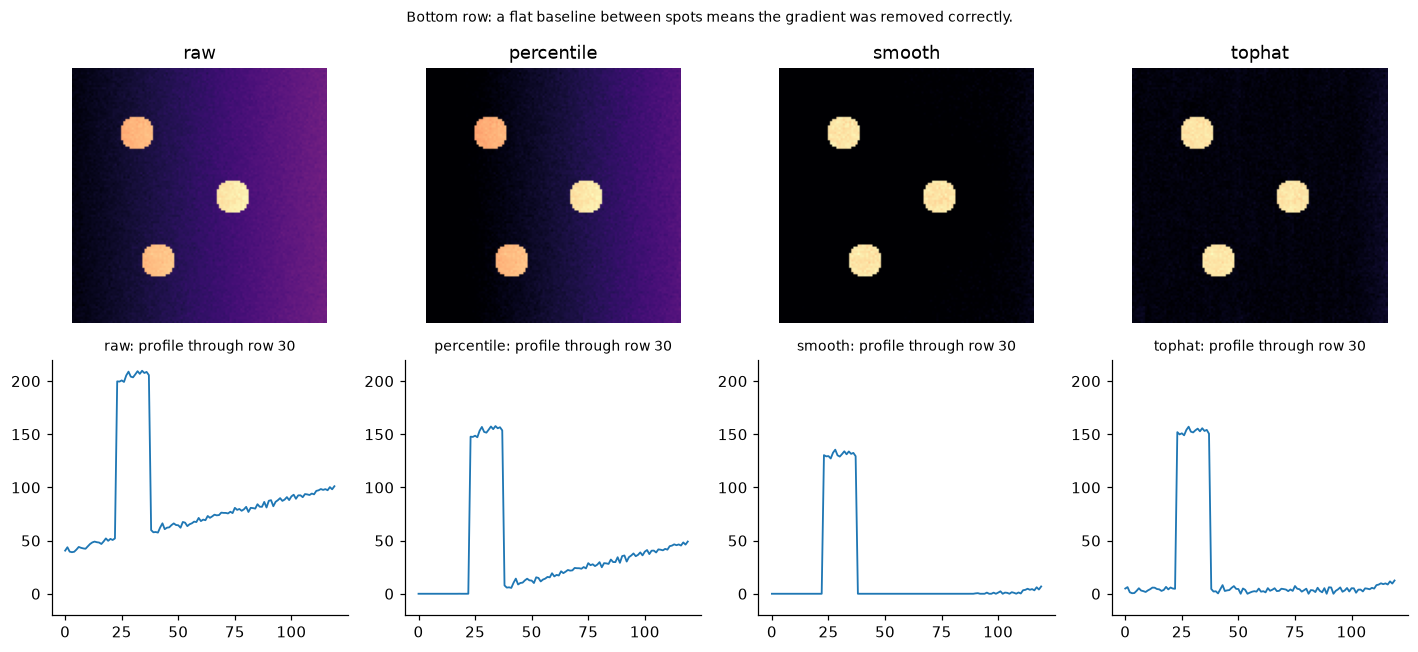

In [7]:
from hive.baseline import apply_baseline_subtraction

# A phantom with an uneven illumination gradient + bright spots.
yy, xx = np.mgrid[0:120, 0:120]
gradient = 40 + 60 * (xx / 119)                       # illumination ramps left->right
phantom = gradient.astype(np.float32)
for (cy, cx) in [(30, 30), (60, 75), (90, 40)]:
    phantom[(yy - cy) ** 2 + (xx - cx) ** 2 < 64] += 150
phantom += RNG.normal(0, 2, phantom.shape).astype(np.float32)

results = {'raw': (phantom, None)}
for method, kwargs in [('percentile', {'percentile': 20}), ('smooth', {'sigma': 15}),
                       ('tophat', {'tophat_radius': 15})]:
    results[method] = apply_baseline_subtraction(phantom, method=method, **kwargs)

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, (name, (corrected, _)) in enumerate(results.items()):
    axes[0, i].imshow(corrected); axes[0, i].set_title(name); axes[0, i].axis('off')
    axes[1, i].plot(corrected[30, :], lw=1.2)
    axes[1, i].set_title(f'{name}: profile through row 30', fontsize=9)
    axes[1, i].set_ylim(-20, 220)
fig.suptitle('Bottom row: a flat baseline between spots means the gradient was removed correctly.', fontsize=9)
plt.tight_layout(); plt.show()

Look at the bottom row. `percentile` leaves the ramp intact (the baseline still rises
left→right) because a single scalar cannot describe a gradient. `smooth` and `tophat` both
flatten it — but watch the baseline immediately *around* each spot in the `smooth` panel:
it dips below zero. That is the halo artifact, and it will bias any measurement that
includes the pixels near an object's edge.

---
## 3. Otsu thresholding — interactive explorer

**Otsu (1979)** picks the threshold that minimizes intra-class variance — equivalently,
maximizes between-class variance — of a bimodal intensity histogram. For each candidate
threshold *t* splitting pixels into background and foreground:

$$\sigma^2_b(t) = \omega_0(t)\,\omega_1(t)\,[\mu_0(t) - \mu_1(t)]^2$$

Otsu chooses the *t* maximizing this. It assumes a **bimodal** histogram; on a sparse image
where 99% of pixels are background, the histogram is effectively unimodal and Otsu drifts.

### About `threshold_scale`

HIVE multiplies the Otsu value by `threshold_scale`. **This is an empirical knob, not part
of Otsu's method.** The legacy default of `1.2` silently made every run 20% more conservative
than the published algorithm. HIVE defaults to `1.0` (true Otsu) and records whatever you used.

Drag the slider below to see how threshold choice changes the object count.

In [8]:
import plotly.graph_objects as go
from skimage import filters, measure
from hive.preprocessing import prepare_image
from hive.config import PreprocessConfig

# A realistic-ish field: cells of varying brightness on an uneven background.
field = np.full((160, 160), 30, dtype=np.float32)
field += (np.mgrid[0:160, 0:160][1] / 159 * 25).astype(np.float32)
truth = 0
for (cy, cx, r, amp) in [(40, 40, 9, 120), (40, 110, 8, 90), (100, 55, 10, 150),
                         (120, 120, 7, 60), (75, 85, 9, 110), (135, 35, 6, 45)]:
    yy, xx = np.mgrid[0:160, 0:160]
    field[(yy - cy) ** 2 + (xx - cx) ** 2 < r ** 2] += amp
    truth += 1
field += RNG.normal(0, 3, field.shape).astype(np.float32)
print(f'phantom contains {truth} cells (ground truth)')

prep = prepare_image(field, PreprocessConfig(baseline_method='tophat', tophat_radius=20,
                                            gaussian_sigma=1.0, use_clahe=True), channel='gray')
seg_img = prep.segmentation
otsu = filters.threshold_otsu(seg_img)
print(f'Otsu threshold on the segmentation image = {otsu:.3f}')

phantom contains 6 cells (ground truth)
Otsu threshold on the segmentation image = 0.385


In [9]:
# Interactive: sweep threshold_scale and watch the object count respond.
scales = np.round(np.arange(0.4, 2.05, 0.1), 2)
frames, counts = [], []
for s in scales:
    mask = seg_img > otsu * s
    n = measure.label(mask).max()
    counts.append(n)
    frames.append(go.Frame(name=str(s), data=[go.Heatmap(z=mask.astype(int), colorscale='Magma',
                                                         showscale=False)]))

fig = go.Figure(
    data=[go.Heatmap(z=(seg_img > otsu * scales[0]).astype(int), colorscale='Magma', showscale=False)],
    frames=frames,
)
fig.update_layout(
    title=f'Drag: threshold_scale x Otsu ({otsu:.3f}).  Ground truth = {truth} cells',
    height=520, width=560, yaxis=dict(autorange='reversed', scaleanchor='x'),
    sliders=[{'active': 0, 'currentvalue': {'prefix': 'threshold_scale = '},
              'steps': [{'label': f'{s}  (n={c})', 'method': 'animate',
                         'args': [[str(s)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}}]}
                        for s, c in zip(scales, counts)]}],
)
fig.show()

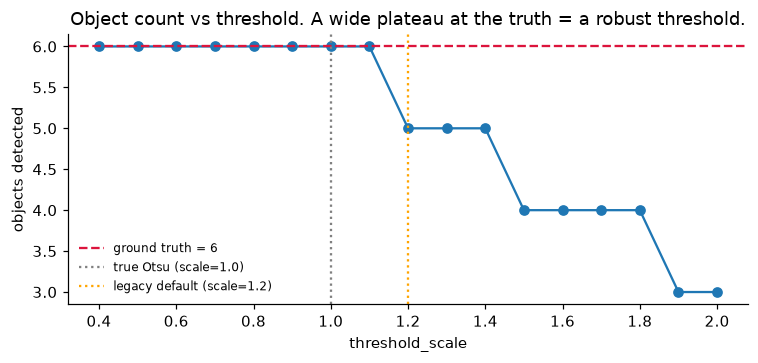

Read this plot before trusting a count: if your count sits on a steep slope, it is an artifact of the threshold, not a property of the sample.


In [10]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(scales, counts, marker='o', lw=1.5)
ax.axhline(truth, ls='--', c='crimson', label=f'ground truth = {truth}')
ax.axvline(1.0, ls=':', c='gray', label='true Otsu (scale=1.0)')
ax.axvline(1.2, ls=':', c='orange', label='legacy default (scale=1.2)')
ax.set_xlabel('threshold_scale'); ax.set_ylabel('objects detected')
ax.set_title('Object count vs threshold. A wide plateau at the truth = a robust threshold.')
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

print('Read this plot before trusting a count: if your count sits on a steep slope,',
      'it is an artifact of the threshold, not a property of the sample.')

---
## 4. Segmentation cleanup

Raw thresholded masks carry artifacts. HIVE filters **label arrays**, not boolean masks, so
an object survives or dies whole (filtering a mask and re-labelling can split one rejected
object into several surviving fragments).

- **Debris** (`min_size`) — shot noise, dust, out-of-focus specks.
- **Clumps** (`max_size`) — merged cells, saturation bleed.
- **Edge objects** (`clear_border`) — truncated by the field of view, so their area and
  morphology are lower bounds, not measurements. Including them biases mean size *down*.
- **Holes** (`hole_size`) — bounded, so genuine lumens survive.

Every filter reports what it removed. Silent filtering is how a "cell count" quietly becomes
an artifact of a debris threshold nobody wrote down.

cleanup report: 7 -> 6 objects (1 removed); 1 edge-touching
  - removed 1 edge-touching objects


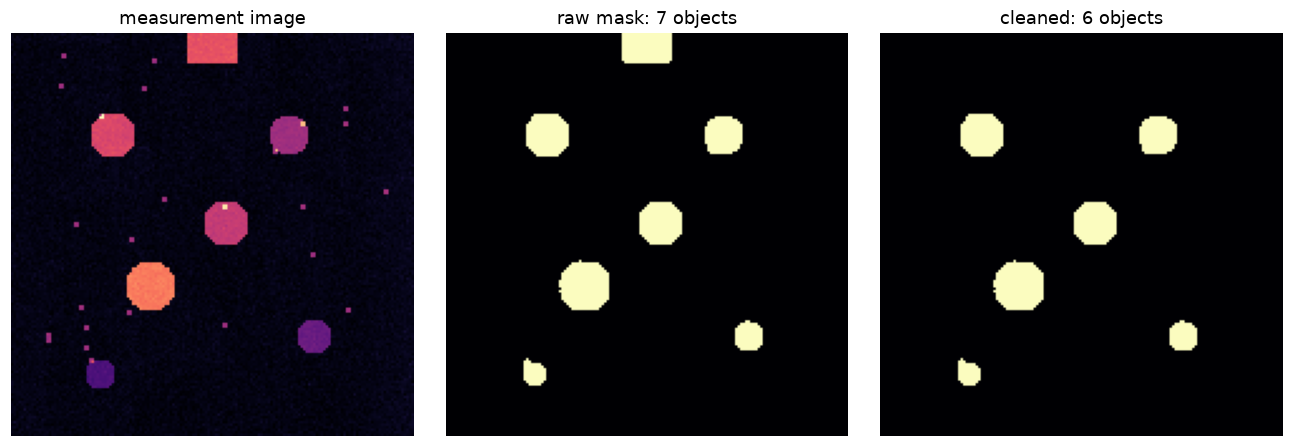

In [11]:
from hive.segmentation import segment
from hive.cleanup import clean_labels
from hive.config import SegmentationConfig

# Add junk to the phantom: debris specks and an edge-touching object.
dirty = field.copy()
for _ in range(25):
    y, x = RNG.integers(5, 155, 2)
    dirty[y:y+2, x:x+2] += 90                 # tiny debris
dirty[0:12, 70:90] += 130                     # object clipped by the top edge

prep_d = prepare_image(dirty, PreprocessConfig(baseline_method='tophat', tophat_radius=20,
                                              gaussian_sigma=1.0), channel='gray')
raw_labels = segment(prep_d.segmentation, SegmentationConfig(min_size=0, hole_size=0))

cfg_clean = SegmentationConfig(min_size=40, max_size=0, hole_size=20, clear_border=True)
clean, report = clean_labels(raw_labels, cfg_clean)

print('cleanup report:', report.summary())
for step in report.steps: print('  -', step)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(prep_d.measurement); axes[0].set_title('measurement image')
axes[1].imshow(raw_labels > 0); axes[1].set_title(f'raw mask: {raw_labels.max()} objects')
axes[2].imshow(clean > 0); axes[2].set_title(f'cleaned: {clean.max()} objects')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

---
## 5. Measurement

Now we measure the cleaned labels **against the measurement image**.

The column to care about is usually **`integrated_intensity`** (mean × area), not
`intensity_mean`. Because background is already removed, it equals the background-corrected
integrated density — the *total* signal in the object. Mean intensity alone confounds
a small bright object with a large dim one.

In [12]:
from hive.measurements import measure_objects, summarize_measurements

df = measure_objects(clean, prep_d.measurement, image_name='phantom.tif',
                     voxel_size_xy=0.5, unit='um')
print(f'{len(df)} objects measured\n')
cols = ['label', 'area_px', 'area_um2', 'intensity_mean', 'integrated_intensity',
        'eccentricity', 'solidity']
display(df[cols].round(2))

print('\nper-image summary:')
display(summarize_measurements(df, 'phantom.tif', unit='um').round(2))

6 objects measured



,label,area_px,area_um2,intensity_mean,integrated_intensity,eccentricity,solidity
0,1,251.0,62.75,129.04,32388.59,0.18,1.00
1,2,197.0,49.25,98.40,19385.70,0.28,0.97
2,3,249.0,62.25,117.91,29359.72,0.00,1.00
3,4,326.0,81.50,148.10,48279.39,0.19,0.98
4,5,111.0,27.75,67.73,7518.56,0.26,0.98
5,6,76.0,19.00,54.95,4176.37,0.58,0.96



per-image summary:


,image,object_count,total_area_um2,mean_area_um2,median_area_um2,mean_intensity,total_integrated_intensity
0,phantom.tif,6,302.5,50.42,55.75,102.69,141108.32


---
## 6. Arborization analysis

This is where branching structure gets quantified. Four steps.

### 6.1 Skeletonization

Medial-axis thinning erodes a mask to a 1-pixel centreline while preserving topology.
2D uses Zhang–Suen-family thinning; 3D uses **Lee, Kashyap & Chu (1994)**.

### 6.2 Branch topology — and why neighbour-counting is wrong

The obvious classifier is *count each skeleton pixel's neighbours*: 1 = tip, ≥3 = junction.
It has a specific failure. Consider a single pixel resting on a straight line:

```
.  .  X  .  .        X touches 3 line pixels below it.
L  L  L  L  L        Neighbour count says 3 -> "junction".
```

But no branch *departs* there — X's three neighbours are all mutually adjacent. It's a bump.
This is not academic: it broke spur pruning during development, because a bump misclassified
as a junction became immune to removal and held a phantom junction open forever.

The fix is the **Rutovitz crossing number** — count 0→1 transitions around the 8-neighbour ring:

$$CN(p) = \tfrac{1}{2}\sum_i |P_{i+1} - P_i|$$

For the bump the ring reads `00011100` — one transition, `CN=1`, a **tip**. For a real
T-junction it reads `10100010` — three transitions, `CN=3`, a **junction**. `CN=2` is an
ordinary path pixel.

### 6.3 Length with diagonal correction

Counting skeleton pixels **underestimates length by ~29%** on diagonals: a diagonal step spans
√2 but counts as 1. HIVE sums the true Euclidean distance of every adjacent pair.

### 6.4 Sholl analysis

**Sholl (1953).** Place concentric shells at increasing radius from the soma and count how
many times the arbor crosses each. *N(r)* profiles complexity against distance — separating
a compact bushy arbor from a sparse far-reaching one even when both have identical branch counts.

In [13]:
from hive.arborization import (skeletonize_mask, crossing_number, find_endpoints,
                               find_branch_points, skeleton_length, skeleton_metrics)

# Demonstrate the bump problem concretely.
demo = np.zeros((9, 11), bool)
demo[5, 1:10] = True     # a straight line
demo[4, 5] = True        # one pixel resting on it

from scipy import ndimage as ndi
kernel = np.ones((3, 3), np.uint8); kernel[1, 1] = 0
degree = ndi.convolve(demo.astype(np.uint8), kernel, mode='constant')
cn = crossing_number(demo)

print('The bump pixel at (4,5):')
print(f'  raw neighbour count = {degree[4,5]}  -> would be called a JUNCTION (wrong)')
print(f'  crossing number     = {cn[4,5]}  -> correctly called a TIP')
print(f'  find_branch_points flags it? {find_branch_points(demo)[4,5]}')
print(f'  find_endpoints flags it?     {find_endpoints(demo)[4,5]}')

The bump pixel at (4,5):
  raw neighbour count = 3  -> would be called a JUNCTION (wrong)
  crossing number     = 1  -> correctly called a TIP
  find_branch_points flags it? False
  find_endpoints flags it?     True


In [14]:
# Diagonal length correction, with an exactly known answer.
diag = np.zeros((40, 40), bool)
for i in range(30): diag[5 + i, 5 + i] = True     # 30 px -> 29 steps of sqrt(2)

print(f'naive pixel count : {diag.sum()}')
print(f'HIVE length       : {skeleton_length(diag):.3f}')
print(f'exact truth       : {29 * np.sqrt(2):.3f}  (29 steps x sqrt(2))')
print(f'error if you just count pixels: {abs(diag.sum() - 29*np.sqrt(2)) / (29*np.sqrt(2)) * 100:.1f}%')

naive pixel count : 30
HIVE length       : 41.012
exact truth       : 41.012  (29 steps x sqrt(2))
error if you just count pixels: 26.9%


In [15]:
import math
from skimage.draw import line, disk
from skimage.morphology import binary_dilation, disk as sedisk

# A synthetic neuron with KNOWN topology: a soma, 4 primary arms, each forking
# once into 2 daughters. Ground truth: 5 junctions (soma + 4 forks), 8 tips,
# 12 branch segments (4 primary + 8 daughters).
S, C, R_FORK, R_TIP = 181, 90, 40, 75

def build_neuron():
    n = np.zeros((S, S), bool)
    rr, cc = disk((C, C), 3, shape=n.shape); n[rr, cc] = True          # soma
    for k in range(4):
        th = k * math.pi / 2
        fy = int(round(C + R_FORK*math.sin(th))); fx = int(round(C + R_FORK*math.cos(th)))
        rr, cc = line(C, C, fy, fx); n[rr, cc] = True                  # primary arm
        for d in (-0.5, 0.5):                                          # two daughters
            ty = int(round(C + R_TIP*math.sin(th+d))); tx = int(round(C + R_TIP*math.cos(th+d)))
            rr, cc = line(fy, fx, ty, tx); n[rr, cc] = True
    return binary_dilation(n, sedisk(1))    # give it realistic thickness

neuron = build_neuron()
m = skeleton_metrics(neuron, prune_length=4)
print(f'total neurite length : {m.total_length:.1f} px')
print(f'branch points        : {m.n_branch_points}    (ground truth 5: soma + 4 forks)')
print(f'endpoints            : {m.n_endpoints}    (ground truth 8: 4 arms x 2 tips)')
print(f'branch segments      : {m.n_branches}   (ground truth 12: 4 primary + 8 daughters)')
print(f'spurs pruned         : {m.pruned_spurs}')

total neurite length : 542.0 px
branch points        : 5    (ground truth 5: soma + 4 forks)
endpoints            : 8    (ground truth 8: 4 arms x 2 tips)
branch segments      : 12   (ground truth 12: 4 primary + 8 daughters)
spurs pruned         : 0


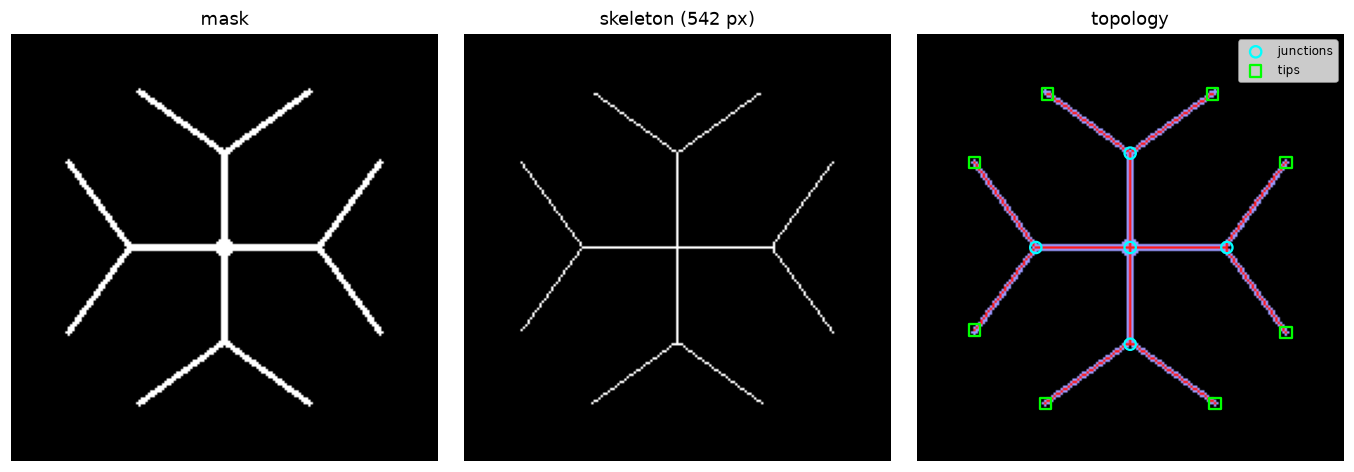

In [16]:
from hive.visualization import create_skeleton_overlay

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.2))
axes[0].imshow(neuron, cmap='gray'); axes[0].set_title('mask')
axes[1].imshow(m.skeleton, cmap='gray'); axes[1].set_title(f'skeleton ({m.total_length:.0f} px)')
axes[2].imshow(create_skeleton_overlay(neuron.astype(float), m.skeleton, neuron))
bp = np.argwhere(find_branch_points(m.skeleton)); ep = np.argwhere(find_endpoints(m.skeleton))
axes[2].scatter(bp[:, 1], bp[:, 0], s=55, facecolors='none', edgecolors='cyan', lw=1.5, label='junctions')
axes[2].scatter(ep[:, 1], ep[:, 0], s=55, marker='s', facecolors='none', edgecolors='lime', lw=1.5, label='tips')
axes[2].legend(fontsize=8, loc='upper right'); axes[2].set_title('topology')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

primary processes    : 4      (ground truth 4)
max intersections    : 8      (ground truth 8, past the forks)
critical radius      : 44.0 px  (forks sit at r=40)
enclosing radius     : 72.0 px  (tips sit at r=75)
ramification index   : 2.00   (= max / primary; each arm doubled)
Sholl coefficient k  : 0.0243

N(r) = [np.int64(4), np.int64(4), np.int64(4), np.int64(4), np.int64(4), np.int64(4), np.int64(4), np.int64(4), np.int64(4), np.int64(4), np.int64(8), np.int64(8), np.int64(8), np.int64(8)] ...


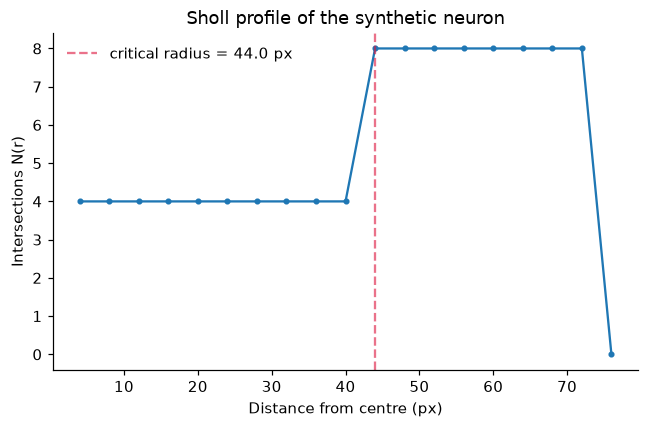

In [17]:
from hive.arborization import sholl_analysis
from hive.visualization import plot_sholl

sholl = sholl_analysis(m.skeleton, center=(C, C), step=4.0)

print(f'primary processes    : {sholl.n_primary}      (ground truth 4)')
print(f'max intersections    : {sholl.max_intersections}      (ground truth 8, past the forks)')
print(f'critical radius      : {sholl.critical_radius:.1f} px  (forks sit at r={R_FORK})')
print(f'enclosing radius     : {sholl.enclosing_radius:.1f} px  (tips sit at r={R_TIP})')
print(f'ramification index   : {sholl.ramification_index:.2f}   (= max / primary; each arm doubled)')
print(f'Sholl coefficient k  : {sholl.regression_coefficient:.4f}')
print()
print(f'N(r) = {list(sholl.intersections[:14])} ...')

plot_sholl(sholl, unit='px', title='Sholl profile of the synthetic neuron'); plt.show()

Read the profile: *N(r)* sits at **4** near the soma (four primary arms), then steps to **8**
past the fork radius, then falls to 0 at the arbor's edge. The **ramification index** of 2.0
says each primary process doubled — exactly the phantom we built.

The **Sholl regression coefficient** *k* comes from the semi-log fit
$\log_{10}(N(r)/\text{area}(r)) = \log_{10}(K) - k\,r$. Normalizing by shell area matters:
a bigger shell samples more space and would show more crossings for purely geometric reasons.
Higher *k* = intersection density falls off faster = a more compact arbor.

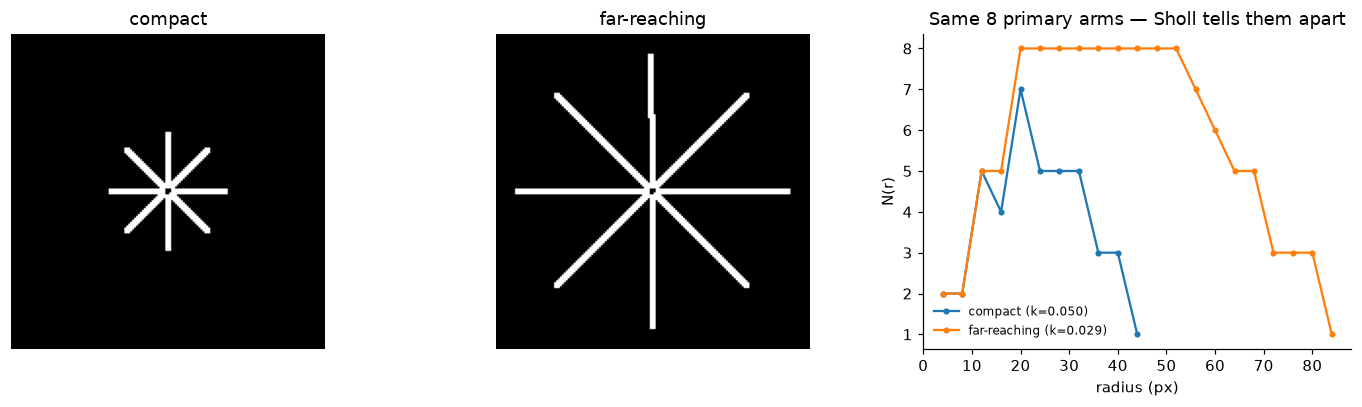

In [18]:
# Sholl separates arbors that branch-counting alone cannot distinguish.
def radial_arbor(n_arms, reach, S=161):
    C = S // 2
    a = np.zeros((S, S), bool)
    for k in range(n_arms):
        th = 2 * np.pi * k / n_arms
        for t in range(3, reach):
            y, x = int(C + t*np.sin(th)), int(C + t*np.cos(th))
            a[y-1:y+2, x-1:x+2] = True
    return a

compact  = radial_arbor(8, 30)    # many short arms
sparse   = radial_arbor(8, 70)    # same count, much longer reach

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, arb, name in [(axes[0], compact, 'compact'), (axes[1], sparse, 'far-reaching')]:
    ax.imshow(arb, cmap='gray'); ax.set_title(name); ax.axis('off')
for arb, name in [(compact, 'compact'), (sparse, 'far-reaching')]:
    mm = skeleton_metrics(arb, prune_length=3)
    sh = sholl_analysis(mm.skeleton, (90, 90), step=4.0)
    axes[2].plot(sh.radii, sh.intersections, marker='o', ms=3, label=f'{name} (k={sh.regression_coefficient:.3f})')
axes[2].set_xlabel('radius (px)'); axes[2].set_ylabel('N(r)')
axes[2].set_title('Same 8 primary arms — Sholl tells them apart'); axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

---
## 7. 3D reconstruction and the rotating GIF

### Anisotropy — read this before rendering

Confocal z-steps are routinely **3–10× the xy pixel size**. Rotating such a volume as if it
were isotropic squashes it: spheres render as ellipsoids that *change shape as they turn*.
`render_rotation` resamples to isotropic voxels by default — pass your real voxel sizes.

### Two projection models

- **MIP** — each output pixel takes the brightest voxel along the ray. Unambiguous and
  depth-agnostic; the standard for fluorescence. Cannot show what's in front of what.
- **Alpha blending** — front-to-back compositing with the Porter–Duff *over* operator:
  $C = \sum_i c_i \alpha_i \prod_{j<i}(1-\alpha_j)$. Conveys depth, but bright foreground
  structures occlude dim ones behind them.

In [19]:
from hive.render3d import render_rotation, save_gif, make_isotropic
from hive.config import RenderConfig

# A 3D phantom: a sphere plus a bar, ANISOTROPIC (z-step 3x the xy pixel).
Z, Y, X = 20, 90, 90
vol = np.zeros((Z, Y, X), np.float32)
zz, yy, xx = np.ogrid[:Z, :Y, :X]
vol[((zz-10)**2 * 9 + (yy-35)**2 + (xx-35)**2) < 200] = 1.0   # a true sphere in PHYSICAL space
vol[8:13, 60:66, 20:70] = 0.65

VOXEL_XY, VOXEL_Z = 1.0, 3.0
iso = make_isotropic(vol, VOXEL_XY, VOXEL_Z)
print(f'anisotropic {vol.shape}  ->  isotropic {iso.shape}   (z upsampled {VOXEL_Z/VOXEL_XY:.0f}x)')

anisotropic (20, 90, 90)  ->  isotropic (60, 90, 90)   (z upsampled 3x)


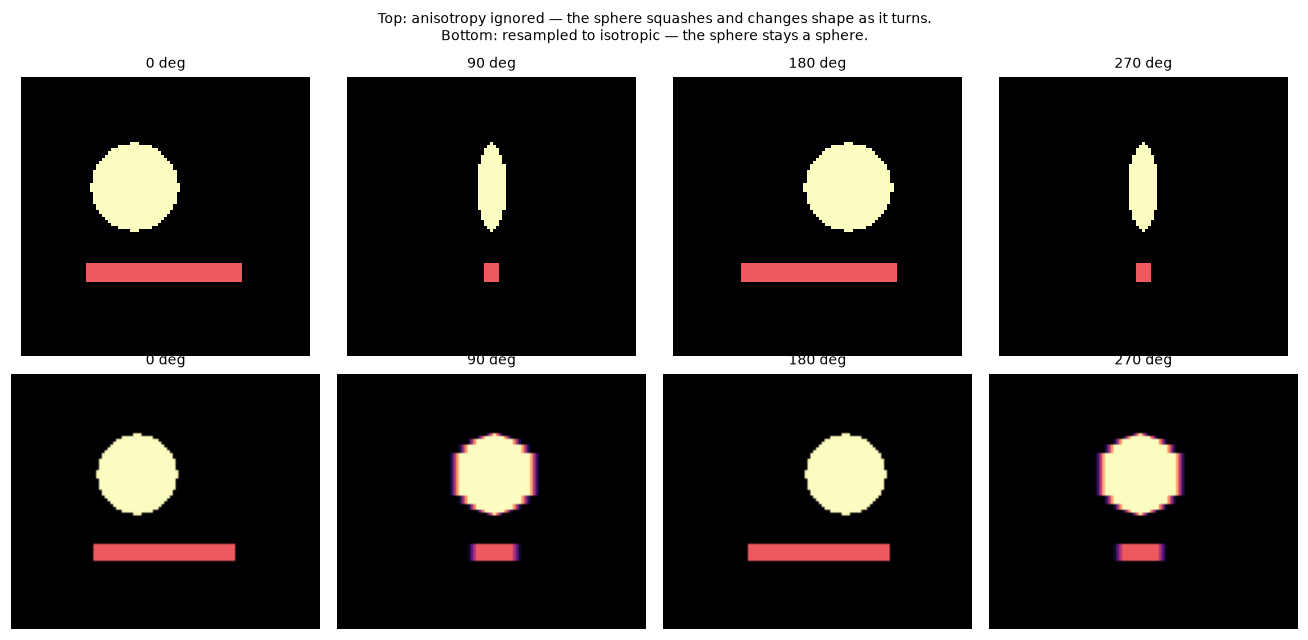

In [20]:
# Why resampling matters: render the SAME volume with and without it.
wrong = render_rotation(vol, RenderConfig(n_frames=4, downsample=1), resample_isotropic=False)
right = render_rotation(vol, RenderConfig(n_frames=4, downsample=1),
                        voxel_size_xy=VOXEL_XY, voxel_size_z=VOXEL_Z, resample_isotropic=True)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axes[0, i].imshow(wrong[i]); axes[0, i].set_title(f'{i*90} deg', fontsize=9)
    axes[1, i].imshow(right[i]); axes[1, i].set_title(f'{i*90} deg', fontsize=9)
for ax in axes.ravel(): ax.axis('off')
axes[0, 0].set_ylabel('NOT resampled'); axes[1, 0].set_ylabel('resampled')
fig.suptitle('Top: anisotropy ignored — the sphere squashes and changes shape as it turns.\n'
             'Bottom: resampled to isotropic — the sphere stays a sphere.', fontsize=9)
plt.tight_layout(); plt.show()

wrote notebook_output/rotation.gif  (22.9 KB, 36 frames)


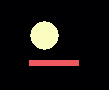

In [21]:
# Render the full rotation and write an optimized GIF.
cfg_render = RenderConfig(mode='mip', n_frames=36, fps=15, colormap='magma', downsample=1)
frames = render_rotation(vol, cfg_render, voxel_size_xy=VOXEL_XY, voxel_size_z=VOXEL_Z)

out = Path('notebook_output'); out.mkdir(exist_ok=True)
gif_path = save_gif(frames, out / 'rotation.gif', fps=cfg_render.fps)
print(f'wrote {gif_path}  ({gif_path.stat().st_size/1024:.1f} KB, {len(frames)} frames)')

from IPython.display import Image as IPyImage, display as ipy_display
ipy_display(IPyImage(filename=str(gif_path)))

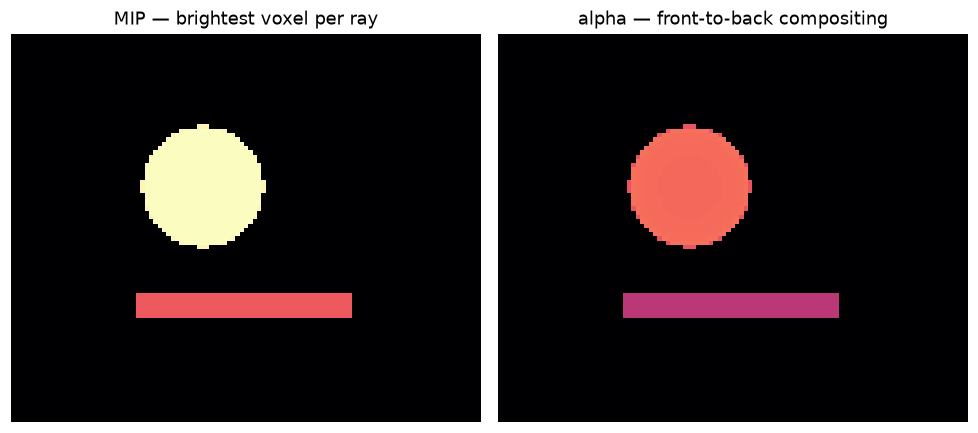

In [22]:
# Compare MIP against alpha blending.
mip_f   = render_rotation(vol, RenderConfig(mode='mip', n_frames=1, downsample=1),
                          voxel_size_xy=VOXEL_XY, voxel_size_z=VOXEL_Z)
alpha_f = render_rotation(vol, RenderConfig(mode='alpha', n_frames=1, downsample=1, alpha_scale=0.7),
                          voxel_size_xy=VOXEL_XY, voxel_size_z=VOXEL_Z)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
axes[0].imshow(mip_f[0]);   axes[0].set_title('MIP — brightest voxel per ray')
axes[1].imshow(alpha_f[0]); axes[1].set_title('alpha — front-to-back compositing')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

---
## 8. Full 3D pipeline and export

Everything above, wired together. `analyze_zstack` returns an `AnalysisResult` object
(not a bare tuple), writes the volume/mask TIFFs with embedded voxel spacing, the
interactive Plotly viewer, the OBJ mesh, and CSV/Excel reports whose **Settings** sheet
records every parameter that produced them.

In [23]:
import tifffile
from hive.config import HiveConfig, ArborConfig, SegmentationConfig
from hive.pipeline import analyze_zstack

stack_dir = Path('notebook_output'); stack_dir.mkdir(exist_ok=True)
stack_path = stack_dir / 'demo_stack.tif'

# A z-stack with a REAL axial intensity gradient — the thing legacy code flattened.
demo_stack = np.full((12, 90, 90), 100, np.uint16)
zz, yy, xx = np.ogrid[:12, :90, :90]
for z in range(12):
    blob = ((yy - 45)**2 + (xx - 45)**2 < 200)[0]
    demo_stack[z][blob] = 800 + z * 60      # brightness rises with depth
tifffile.imwrite(stack_path, demo_stack)

cfg = HiveConfig(
    input_path=str(stack_path), output_folder=str(stack_dir / 'results'),
    mode='3d', channel='gray',
    voxel_size_xy=0.3, voxel_size_z=1.0, voxel_unit='um',
    preprocess=PreprocessConfig(baseline_method='percentile', baseline_percentile=25,
                                gaussian_sigma=0.8),
    segmentation=SegmentationConfig(min_size=100),
    arbor=ArborConfig(enabled=False),
    render=RenderConfig(n_frames=24, downsample=1, colormap='viridis'),
)
result = analyze_zstack(cfg, render_gif=True)

print(f'objects: {result.object_count}')
print(f'cleanup: {result.cleanup.summary()}')
display(result.measurements.round(2))

objects: 1
cleanup: 1 -> 1 objects (0 removed)


,image,label,volume_voxels,bbox-0,bbox-1,bbox-2,bbox-3,bbox-4,bbox-5,centroid-0,centroid-1,centroid-2,equivalent_diameter_area,extent,solidity,intensity_mean,intensity_max,intensity_min,volume_um3,integrated_intensity
0,demo_stack.tif,1,7452.0,0,31,31,12,60,60,5.5,45.0,45.0,24.23,0.74,0.96,1030.0,1360.0,700.0,670.68,7675560.0


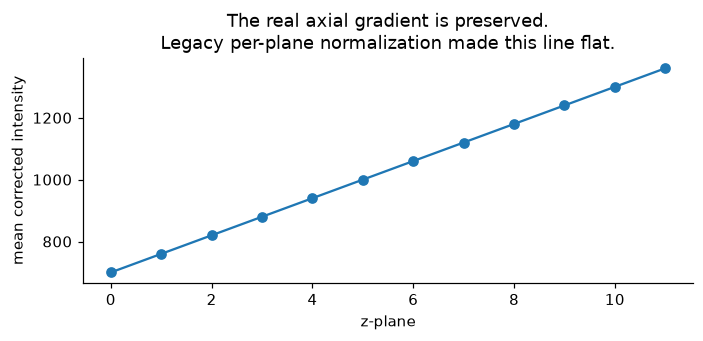

artifacts written:
  viewer_html      HIVE_3D_viewer.html
  mesh_obj         HIVE_3D_mesh.obj
  gif              HIVE_3D_rotation.gif
  excel            HIVE_3D_report.xlsx


In [24]:
# Confirm the axial gradient survived the pipeline.
meas = result.prepared.measurement
planes = [meas[z][meas[z] > 0].mean() if (meas[z] > 0).any() else 0 for z in range(meas.shape[0])]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(planes, marker='o')
ax.set_xlabel('z-plane'); ax.set_ylabel('mean corrected intensity')
ax.set_title('The real axial gradient is preserved.\nLegacy per-plane normalization made this line flat.')
plt.tight_layout(); plt.show()

print('artifacts written:')
for kind, path in result.outputs.items():
    print(f'  {kind:16s} {Path(path).name}')

---
# 9. Scaling up: big images, memory, and parallel runs

Everything above ran on small phantoms. This section is about real data — and it
exists because HIVE has one hard architectural limit worth understanding before you
point it at a large dataset.

## The limit

**HIVE loads volumes whole.** There is no chunked or out-of-core path. Peak memory is
roughly a fixed multiple of the data:

| Stage | Multiplier (measured, real RSS) |
|---|---|
| your file as float32 | **2×** the uint16 file — cameras give 16-bit, HIVE needs float |
| the 3D pipeline on top | **~5.4×** the float32 volume |
| **CLAHE on a large 2D image** | **~18×** the image — dominates everything else |
| each parallel worker | **×** its own full working set |

So a 35 GB uint16 stack becomes 70 GB as float32 and peaks near **700 GB**. That is not
a tuning problem — it's the architecture. HIVE now checks the file header *before*
decoding and refuses with an actionable message rather than silently killing your kernel.

## Why float32 is *not* the thing to blame

A natural instinct is "make it uint16 and save half". True, but it's a **2× lever on a
20× problem**. Even a perfect zero-copy uint16 pipeline still needs the whole volume
resident plus room to work. The wall isn't the dtype — it's holding the entire volume
at once.

## What to do instead

1. **Process plane by plane in 2D.** If your objects live within single planes, this
   works today and is the fastest path to an answer.
2. **Downsample or crop.** 4× per axis is 64× smaller. Fine for counts and gross
   morphology; it erases fine neurites, so not for arborization.
3. **Chunked/out-of-core** (zarr + dask) if you truly need 3D over a huge volume. That
   is a real project, not a flag.

In [25]:
from hive.io_utils import memory_report

# ---- EDIT ME: the shape of ONE of your images, or a path to a .tif -----------
YOUR_SHAPE = (12671, 12671)      # e.g. one plane of a large stack
WORKERS    = 6
# ------------------------------------------------------------------------------

print("=== one plane, CLAHE ON ===")
print(memory_report(YOUR_SHAPE, workers=WORKERS, use_clahe=True)["summary"])
print("\n=== one plane, CLAHE OFF ===")
print(memory_report(YOUR_SHAPE, workers=WORKERS, use_clahe=False)["summary"])

# And the same data as ONE 3D volume, for comparison:
print("\n=== all 109 planes as a single 3D volume ===")
print(memory_report((109, *YOUR_SHAPE), workers=1)["summary"])

print("\nNote: these estimates are deliberately CONSERVATIVE (they use a 10x pipeline")
print("factor). Measured peak on a real 12671^2 plane with CLAHE off was 4.97 GB,")
print("about 30% below the estimate -- so if the report says 5 workers, 6 usually run.")

=== one plane, CLAHE ON ===
shape            (12671, 12671)
as float32       642.2 MB
peak per worker  11.6 GB  (18x, CLAHE-dominated)
workers          6  ->  69.4 GB total
machine RAM      16.7 GB
verdict          DOES NOT FIT   (max safe workers here: 1)
hint             use_clahe=False cuts this ~2.7x on large 2D images

=== one plane, CLAHE OFF ===
shape            (12671, 12671)
as float32       642.2 MB
peak per worker  6.4 GB  (10x)
workers          6  ->  38.5 GB total
machine RAM      16.7 GB
verdict          DOES NOT FIT   (max safe workers here: 2)

=== all 109 planes as a single 3D volume ===
shape            (109, 12671, 12671)
as float32       70.0 GB
peak per worker  700.0 GB  (10x)
workers          1  ->  700.0 GB total
machine RAM      16.7 GB
verdict          DOES NOT FIT   (max safe workers here: 1)

Note: these estimates are deliberately CONSERVATIVE (they use a 10x pipeline
factor). Measured peak on a real 12671^2 plane with CLAHE off was 4.97 GB,
about 30% below t

---
## 9.1 The CLAHE decision — the biggest single lever

CLAHE (contrast enhancement) costs **~18× the image size** on a large 2D image. That is
inherent to scikit-image's implementation: it does **not** shrink with `kernel_size`
(verified at 64, 256, and the default — all ~17–19×).

On one real-sized plane, measured:

| | CLAHE on | CLAHE off |
|---|---|---|
| peak memory | 13.2 GB | **4.97 GB** |
| time | 22.5 s | **14.8 s** |
| workers fitting in 39 GB | 2 | **6** |
| objects detected | 399 | 399 |
| measured intensity | 3599.9 | 3599.9 |

**Identical results, 2.7× less memory, 5× faster wall-clock.**

Why identical? Two reasons. First, top-hat background subtraction has *already* removed
the uneven illumination that CLAHE exists to fix, so its marginal benefit is often small.
Second — and this is the two-image contract paying off — **CLAHE never touches the
measurement image**, so intensity is identical *by construction*. Only detection could
differ.

> **Do not take this on faith.** That test used high-contrast phantoms. CLAHE earns its
> keep on *dim* objects under uneven illumination, which those phantoms don't have. The
> cell below runs the A/B on **your** data. If the counts agree, turn it off.

In [26]:
import time
from pathlib import Path

import numpy as np
import tifffile

from hive.cleanup import clean_labels
from hive.config import PreprocessConfig, SegmentationConfig
from hive.io_utils import collect_image_paths, load_image
from hive.measurements import measure_objects
from hive.preprocessing import prepare_image
from hive.segmentation import segment

# ---- EDIT ME ------------------------------------------------------------------
YOUR_PLANES  = None      # e.g. Path("planes")  -> a folder of your .tif planes
N_CALIBRATE  = 3         # how many planes to test (3-5 is plenty)
TOPHAT_RADIUS = 25       # MUST exceed your largest real object
MIN_SIZE      = 200      # debris threshold, px
PIXEL_SIZE    = 0.35     # um per pixel
# -------------------------------------------------------------------------------

if YOUR_PLANES is None:
    # Stand-in planes so this cell runs out of the box. Deliberately includes
    # DIM objects on an uneven background -- the case where CLAHE might matter.
    demo = Path("notebook_output/calib"); demo.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(0)
    for i in range(N_CALIBRATE):
        S = 900
        img = np.full((S, S), 400, np.float32)
        img += np.linspace(0, 250, S, dtype=np.float32)[None, :]   # illumination ramp
        img += rng.normal(0, 12, (S, S)).astype(np.float32)
        yy, xx = np.mgrid[0:S, 0:S]
        for k in range(40):
            cy, cx = rng.integers(40, S - 40, 2)
            amp = 260 if k % 2 else 900          # half bright, half DIM
            img[(yy - cy) ** 2 + (xx - cx) ** 2 < 100] += amp
        tifffile.imwrite(demo / f"z{i:02d}.tif", np.clip(img, 0, 65535).astype(np.uint16))
    YOUR_PLANES = demo
    print(f"no YOUR_PLANES set -> using {N_CALIBRATE} stand-in planes with dim + bright objects\n")

paths = collect_image_paths(YOUR_PLANES)[:N_CALIBRATE]
seg_cfg = SegmentationConfig(min_size=MIN_SIZE)

rows = []
for use_clahe in (True, False):
    counts, t0 = [], time.perf_counter()
    for p in paths:
        prep = prepare_image(
            load_image(p),
            PreprocessConfig(baseline_method="tophat", tophat_radius=TOPHAT_RADIUS,
                             gaussian_sigma=1.0, use_clahe=use_clahe),
            channel="gray",
        )
        labels, _ = clean_labels(segment(prep.segmentation, seg_cfg), seg_cfg)
        df = measure_objects(labels, prep.measurement, p.name, voxel_size_xy=PIXEL_SIZE, unit="um")
        counts.append(len(df))
    rows.append({"CLAHE": "on" if use_clahe else "off", "objects": counts,
                 "total": sum(counts), "seconds": round(time.perf_counter() - t0, 1)})

import pandas as pd
display(pd.DataFrame(rows))

on, off = rows[0]["total"], rows[1]["total"]
delta = abs(on - off) / max(on, 1) * 100
print(f"\nCLAHE on found {on} objects, off found {off}  ->  {delta:.1f}% difference")
if delta < 2:
    print("VERDICT: agreement is within 2%. Use use_clahe=False (--no-clahe):")
    print("         ~2.7x less memory, ~3x more parallel workers, same answer.")
else:
    print("VERDICT: CLAHE changes your detections meaningfully -- KEEP IT ON.")
    print("         Budget ~18x the image size in memory and use fewer workers.")
print("\nAlso check a boundary overlay by eye before trusting either number.")

no YOUR_PLANES set -> using 3 stand-in planes with dim + bright objects



,CLAHE,objects,total,seconds
0,on,"[20, 19, 19]",58,1.7
1,off,"[20, 19, 19]",58,0.9



CLAHE on found 58 objects, off found 58  ->  0.0% difference
VERDICT: agreement is within 2%. Use use_clahe=False (--no-clahe):
         ~2.7x less memory, ~3x more parallel workers, same answer.

Also check a boundary overlay by eye before trusting either number.


---
## 9.2 Parallel batches

Images are independent, so a batch parallelises almost perfectly. `analyze_folder`
takes a `workers` argument (CLI: `--workers`).

**The catch:** each worker holds its **own** full working set, so peak memory is
`workers × per-image peak`. Oversubscribing doesn't fail fast — it swaps, and on macOS
that means the machine crawls for a very long time. HIVE warns you if the count won't fit.

Parallel and sequential results are byte-identical (there's a test pinning it), and every
row stays attached to the image it came from.

For 109 real-sized planes, measured: **~26 min at 1 worker, ~4 min at 6.**

In [27]:
from hive.config import ArborConfig, HiveConfig, PreprocessConfig, SegmentationConfig
from hive.pipeline import analyze_folder

# ---- EDIT ME: your real run ---------------------------------------------------
INPUT_FOLDER = YOUR_PLANES          # folder of .tif planes
OUTPUT_FOLDER = "notebook_output/batch_results"
USE_CLAHE    = False                # <- set from the A/B verdict above
WORKERS      = 4                    # start conservative; raise if RAM allows
ARBORIZATION = False                # True adds branch + Sholl metrics (slower)
# -------------------------------------------------------------------------------

cfg = HiveConfig(
    input_path=str(INPUT_FOLDER),
    output_folder=OUTPUT_FOLDER,
    mode="2d",
    channel="gray",
    voxel_size_xy=PIXEL_SIZE,
    voxel_unit="um",
    save_intermediate=False,        # skip QC PNGs: on a big batch they dominate the disk
    preprocess=PreprocessConfig(baseline_method="tophat", tophat_radius=TOPHAT_RADIUS,
                                gaussian_sigma=1.0, use_clahe=USE_CLAHE),
    segmentation=SegmentationConfig(min_size=MIN_SIZE),
    arbor=ArborConfig(enabled=ARBORIZATION),
)

t0 = time.perf_counter()
out = analyze_folder(cfg, workers=WORKERS)
print(f"done in {time.perf_counter()-t0:.1f} s")

measurements, summary = out["measurements"], out["summary"]
print(f"{len(measurements)} objects across {len(summary)} images")
if out["errors"]:
    print(f"\n{len(out['errors'])} file(s) FAILED (batch continued):")
    for name, err in out["errors"]:
        print(f"  {name}: {err}")

display(summary.head())
display(measurements.head())
print(f"\nCSV + Excel written to {Path(OUTPUT_FOLDER).resolve()}")

done in 8.8 s
58 objects across 3 images


,image,object_count,total_area_um2,mean_area_um2,median_area_um2,mean_intensity,total_integrated_intensity
0,z00.tif,20,737.450,36.872500,36.8725,933.256137,5.618202e+06
1,z01.tif,19,738.185,38.851842,36.8725,933.794292,5.627329e+06
2,z02.tif,19,740.390,38.967895,36.8725,936.316914,5.657933e+06


,image,label,area_px,bbox-0,bbox-1,bbox-2,bbox-3,centroid-0,centroid-1,eccentricity,...,axis_major_length,axis_minor_length,orientation,extent,intensity_mean,intensity_max,intensity_min,area_um2,perimeter_um,integrated_intensity
0,z00.tif,1,301.0,32,111,51,130,41.0,120.0,0.0,...,19.57692,19.57692,-0.785398,0.833795,929.488342,960.0,889.0,36.8725,21.099495,279775.991028
1,z00.tif,2,301.0,64,272,83,291,73.0,281.0,0.0,...,19.57692,19.57692,-0.785398,0.833795,932.810608,968.0,904.0,36.8725,21.099495,280775.992981
2,z00.tif,3,301.0,69,389,88,408,78.0,398.0,0.0,...,19.57692,19.57692,-0.785398,0.833795,929.710938,968.0,899.0,36.8725,21.099495,279842.992188
3,z00.tif,4,301.0,88,530,107,549,97.0,539.0,0.0,...,19.57692,19.57692,-0.785398,0.833795,933.295654,968.0,903.0,36.8725,21.099495,280921.991943
4,z00.tif,5,301.0,101,621,120,640,110.0,630.0,0.0,...,19.57692,19.57692,-0.785398,0.833795,935.378723,969.0,902.0,36.8725,21.099495,281548.995667



CSV + Excel written to /home/rush/Downloads/HIVE-main/notebook_output/batch_results


---
## 9.3 Would the GPU help? Measured: no — use more CPU workers

PyTorch on Apple MPS is genuinely fast at HIVE's hot spot. On a 12671² plane the top-hat
background goes **3.74 s → 0.38 s, a 9.8× speedup, with a numerically identical result**
(max difference `0.00e+00`).

So why not use it? **Amdahl's law.** Per-plane profile:

| Stage | Time | Share |
|---|---|---|
| top-hat ← GPU-able | 3.87 s | 27% |
| gaussian ← GPU-able | 0.89 s | 6% |
| threshold + morph + label | 4.91 s | 35% |
| cleanup | 3.88 s | 27% |
| load / measure | 0.54 s | 4% |

Only **34% is GPU-able**, so a 10× speedup on that part gives **1.44× overall** — not 10×.

| 109 planes | wall clock |
|---|---|
| 1 CPU worker | 25.6 min |
| **6 CPU workers** | **4.3 min** |
| 1 GPU worker | 17.8 min |

**Multiprocessing wins by 4×**, because it accelerates *everything*, not 34%. And you
can't have both: MPS is **one device** — six processes contend for it, they don't each
get 10×.

Two more facts worth carrying:

- **Apple unified memory means the GPU shares the same RAM.** MPS gives you *zero* extra
  headroom. It can only ever buy speed, never capacity.
- **On NVIDIA you'd get separate VRAM — but usually *less* than system RAM**, so for a
  memory-bound problem a discrete GPU is often worse.

The MPS path is still wired into `hive.hardware` for the Gaussian, with automatic CPU
fallback. `--hardware` reports what it found, honestly.

The profile also shows where the *real* remaining headroom is: `threshold+morph+label`
(35%) and `cleanup` (27%) are each **bigger than the top-hat**. That's CPU-side work. If
4 minutes isn't fast enough, that's the place to look — not the GPU.

In [28]:
from hive.hardware import describe_hardware

print(describe_hardware())

# Optional: measure the GPU on YOUR machine rather than trusting the table above.
try:
    import torch
    import torch.nn.functional as F
    from scipy.ndimage import grey_dilation, grey_erosion

    if torch.backends.mps.is_available() or torch.cuda.is_available():
        dev = "mps" if torch.backends.mps.is_available() else "cuda"
        S, K = 4096, 51
        img = np.random.default_rng(0).random((S, S), dtype=np.float32)

        t0 = time.perf_counter()
        scratch = np.empty_like(img); ref = np.empty_like(img)
        grey_erosion(img, size=(K, K), output=scratch)
        grey_dilation(scratch, size=(K, K), output=ref)
        t_cpu = time.perf_counter() - t0

        t0 = time.perf_counter()
        t = torch.from_numpy(img).to(dev)[None, None]
        mx = lambda x, kh, kw: F.max_pool2d(x, (kh, kw), stride=1, padding=(kh // 2, kw // 2))
        # erosion = min filter = -maxpool(-x); separable into (1,K) then (K,1)
        e = -mx(-t, 1, K); e = -mx(-e, K, 1)
        d = mx(e, 1, K);   d = mx(d, K, 1)            # dilation, separable
        if dev == "mps":
            torch.mps.synchronize()
        got = d[0, 0].cpu().numpy()
        t_gpu = time.perf_counter() - t0

        print(f"\ntop-hat on {S}x{S}:  CPU {t_cpu:.2f}s   {dev.upper()} {t_gpu:.2f}s"
              f"   -> {t_cpu/t_gpu:.1f}x   (max diff {np.abs(ref-got).max():.1e})")
        print("...but that op is only ~34% of a run, so overall gain is ~1.4x.")
        print("Six CPU workers beat one GPU worker by ~4x. Use --workers.")
    else:
        print("\nNo GPU detected -- which costs you very little here; see the table above.")
except ImportError:
    print("\ntorch not installed (that is fine -- the GPU would not have helped anyway).")

Active backend : CPU (x86_64)
Device         : cpu
Note           : No GPU detected. This is rarely a problem: the CPU pipeline runs a 31 MB stack in ~1 s. Memory, not compute, is the usual limit.

torch not installed (that is fine -- the GPU would not have helped anyway).


---
## 9.4 Splitting a huge multi-page TIFF safely

If your data is one giant multi-page TIFF, don't open it — read it **page by page**, so
only one plane is ever in memory:

In [29]:
# ---- EDIT ME ------------------------------------------------------------------
BIG_STACK = None                  # e.g. "your_35gb_stack.tif"
SPLIT_TO  = "planes"
# -------------------------------------------------------------------------------

if BIG_STACK is None:
    print("Set BIG_STACK to a multi-page TIFF path to run this.\n")
    print("What it does: reads ONE page at a time, so a 35 GB stack never needs")
    print("more than one plane (~321 MB) in memory at once.")
else:
    out_dir = Path(SPLIT_TO); out_dir.mkdir(parents=True, exist_ok=True)
    with tifffile.TiffFile(BIG_STACK) as tf:
        n = len(tf.pages)
        for i, page in enumerate(tf.pages):
            # page.asarray() decodes ONLY this page.
            tifffile.imwrite(out_dir / f"z{i:03d}.tif", page.asarray())
            if i % 10 == 0:
                print(f"  {i+1}/{n}", end="\r")
    print(f"\nwrote {n} planes to {out_dir.resolve()}")

print("\nZero-pad the filenames (z000, not z0). HIVE sorts lexicographically, so")
print("'z10' would sort before 'z2' -- it warns on inconsistent padding, because a")
print("mis-ordered stack produces a plausible but wrong reconstruction.")

Set BIG_STACK to a multi-page TIFF path to run this.

What it does: reads ONE page at a time, so a 35 GB stack never needs
more than one plane (~321 MB) in memory at once.

Zero-pad the filenames (z000, not z0). HIVE sorts lexicographically, so
'z10' would sort before 'z2' -- it warns on inconsistent padding, because a
mis-ordered stack produces a plausible but wrong reconstruction.


---
## Summary

| Rule | Why |
|---|---|
| Measure on the **measurement** image | Enhancement destroys quantification — 3× reported as 1× |
| Prefer **`integrated_intensity`** | Mean alone confounds small-bright with large-dim |
| Report your **`threshold_scale`** | It's an empirical knob, not part of Otsu |
| Set real **voxel sizes** | Physical units, and correct 3D rendering |
| Check the **count-vs-threshold** plot | A count on a steep slope is a threshold artifact |
| Leave **watershed off** for branched cells | It shatters neurons into fragments |
| Read the **cleanup report** | A filtered-away object is a silent change to your n |
| **A/B test CLAHE** on large images | ~18× memory; often no change in detections |
| Budget **workers × per-image peak** | Oversubscribing swaps rather than failing fast |
| Don't reach for the **GPU** | Only 34% is GPU-able; more CPU workers win by ~4× |

### Next steps

- **Web app:** `streamlit run app.py`
- **Batch CLI:** `python hive_cli.py --mode 2d --input planes --voxel-size-xy 0.35 \
  --unit um --no-clahe --workers 4`
- **Tests:** `pytest tests/ -q` — every phantom above has a ground-truth assertion there.
